# Weeks 3-4 subseasonal bias correction for spring peas - Bourgogne-Franche-Comté
### A reproducible, PBC-*inspired* experiment on real ERA5 data

**Purpose.** Evaluate whether a probabilistic-bias-correction (PBC)-inspired recalibration improves weeks 3-4 probabilistic forecasts of two outcomes that matter for spring peas in Bourgogne-Franche-Comté (BFC): *unusually warm* and *unusually wet* conditions.

**Relation to the MIT model.** The original PBC (Guan et al., *Nature* 2026; [github.com/mouatadid/pbc](https://github.com/mouatadid/pbc), MIT License) corrects **dynamical/AI S2S ensemble hindcasts**, which require licensed data (ECMWF/IRI credentials via `cdsapi`/IRI Data Library) and ~80 GB RAM. Those inputs are **not available in this environment**, so reproducing the original model is infeasible here. As explicitly permitted by the task, we implement a **smaller, clearly-labelled PBC-inspired calibration baseline** and compare it honestly against climatology and a raw statistical forecast.

**Data honesty.** Observations are **genuine ERA5 reanalysis** (Open-Meteo archive, `models=era5`). The 'raw forecast' is a reproducible statistical model built from ERA5 information available **at initialisation** - it is **not** observations in disguise, and **no synthetic data are presented as observations**. We do not invent yield, pesticide, economic or environmental figures.

**Reproducibility.** All logic lives in `experiments/pbc/` and is called here. Runs in Kiro/Ubuntu, Colab and AWS Jupyter via repository-relative paths.

## 0. Environment & reproducible setup
**Purpose:** make `experiments/pbc` importable and route logs to `reports/pbc/experiment.log`. **Method:** locate repo root (folder with `experiments/` + `requirements.txt`). **Output:** importable library + output dirs.

In [1]:
import sys, subprocess
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'experiments').is_dir() and (p / 'requirements.txt').exists():
            return p
    return start

try:
    HERE = Path(__file__).resolve().parent
except NameError:
    HERE = Path.cwd()
REPO_ROOT = find_repo_root(HERE)
if not (REPO_ROOT / 'experiments').is_dir() and 'google.colab' in sys.modules:
    subprocess.run(['git','clone','https://github.com/Eric-Kambire/LegumAmies'], check=False)
    REPO_ROOT = Path('LegumAmies').resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import pandas as pd
from IPython.display import Image, display
from experiments.pbc import pbc_lib as L, run_experiment as R, figures as F
print('Repo root:', REPO_ROOT)
print('BFC points:', L.BFC_POINTS)

Repo root: /home/ubuntu/Downloads/LegumAmies
BFC points: {'Dijon': (47.32, 5.04), 'Besancon': (47.24, 6.02), 'Nevers': (46.99, 3.16), 'Macon': (46.31, 4.83), 'Belfort': (47.64, 6.86)}


## 1. Genuine ERA5 observations for BFC
**Data:** ERA5 reanalysis (Copernicus/ECMWF), served by the Open-Meteo archive (`models=era5`). Daily **2 m mean temperature** (°C) and **precipitation sum** (mm), 1991-2024, averaged over five BFC towns (Dijon, Besançon, Nevers, Mâcon, Belfort).
**Methodology:** a single multi-point request (rate-limit friendly); cached to `reports/pbc/era5_bfc_daily.csv` for reproducibility.
**Verification:** we check geography (coords), date range, and units.
**Limitation:** a 5-point regional average smooths within-region variability.

In [2]:
daily = R.load_or_fetch_era5(R._logger())
print('rows:', len(daily), '| range:', daily['date'].min().date(), '->', daily['date'].max().date())
print('units: t2m_mean_c = degC, precip_mm = mm (ERA5)')
print('missing values:', int(daily[['t2m_mean_c','precip_mm']].isna().sum().sum()))
daily.head()

2026-10-31 23:01:12,007 INFO Loading cached ERA5 from /home/ubuntu/Downloads/LegumAmies/reports/pbc/era5_bfc_daily.csv


rows: 12419 | range: 1991-01-01 -> 2024-12-31
units: t2m_mean_c = degC, precip_mm = mm (ERA5)
missing values: 0


,date,t2m_mean_c,precip_mm
0,1991-01-01,5.68,1.96
1,1991-01-02,6.64,9.74
2,1991-01-03,9.50,1.22
3,1991-01-04,6.68,5.28
4,1991-01-05,5.52,1.96


## 2. Build weeks 3-4 forecast samples (leak-free)
**Purpose:** turn the daily series into subseasonal samples. **Methodology:** for each initialisation date `t0` (1st and 15th of each month), the **weeks 3-4 target** is the mean temperature / precipitation total over valid days `[t0+15, t0+28]`. Predictors use **only** data up to `t0` (recent 14/28-day anomaly persistence + seasonal sin/cos), so there is no temporal leakage. We keep init dates whose target window centre falls in the pea season (Mar-Aug).
**Interpretation:** these are the init→lead pairs a weeks-3-4 system would issue.
**Limitation:** biweekly cadence limits sample count (subseasonal data are inherently scarce).

In [3]:
ds = L.build_samples(daily)
print('total samples:', ds.n_total)
print('init months:', sorted(set(ds.table['init_date'].dt.month)))
print('lead (valid days after init):', ds.meta['lead_days'])
ds.table[['init_date','valid_start','valid_end','target_t2m_mean_c','target_precip_mm','pred_t_anom14','pred_p14']].head()

total samples: 340
init months: [3, 4, 5, 6, 7, 8]
lead (valid days after init): [15, 28]


,init_date,valid_start,valid_end,target_t2m_mean_c,target_precip_mm,pred_t_anom14,pred_p14
0,1991-03-15,1991-03-30,1991-04-12,9.898571,9.36,2.253529,27.10
1,1991-04-01,1991-04-16,1991-04-29,6.824286,28.80,-1.503193,37.64
2,1991-04-15,1991-04-30,1991-05-13,9.348571,42.98,0.341597,10.08
3,1991-05-01,1991-05-16,1991-05-29,13.574286,8.66,-5.951008,53.06
4,1991-05-15,1991-05-30,1991-06-12,15.792857,41.12,-4.648571,21.48


## 3. Event definition, chronological split & the three models
**Event ('unusually'):** above the **upper tercile** (≈ warmest/wettest third), with thresholds computed **per target week-of-year from the TRAIN split only** and applied forward (leak-free).
**Chronological split:** train ≤ 2014, validation 2015-2018, test ≥ 2019. No shuffling.
**Models:**
- **Climatology** - training base rate of the event (reference forecast).
- **Raw forecast** - a *persistence++-inspired* logistic model on init-time predictors, fit on train. A genuine statistical forecast, not observations.
- **PBC-inspired** - isotonic **reliability recalibration** of the raw probabilities, fit on the **validation** split (a held-out calibration set), i.e. learning-enhanced probabilities. This is the PBC-*inspired* step.
**Formulas:** Brier score $BS=\frac1N\sum (p_i-y_i)^2$; Brier skill score $BSS=1-BS/BS_{clim}$; Expected Calibration Error $ECE=\sum_b \frac{n_b}{N}|\bar p_b-\bar y_b|$.
**Interpretation:** lower Brier = better; BSS>0 = better than climatology; lower ECE = better calibrated.
**Limitation:** with a short test period, estimates are noisy - hence the bootstrap below.

In [4]:
# Run the full, logged experiment (saves metrics/predictions/metadata to reports/pbc/).
res = R.run()
for o,_ in R.OUTCOMES:
    r = res['results'][o]
    print(f"[{o}] n={r['n']} test_base_rate={r['base']['test']:.3f}")

2026-10-31 23:01:12,140 INFO Loading cached ERA5 from /home/ubuntu/Downloads/LegumAmies/reports/pbc/era5_bfc_daily.csv


2026-10-31 23:01:12,143 INFO ERA5 daily rows=12419 range=1991-01-01..2024-12-31 nan=0


2026-10-31 23:01:12,247 INFO samples=340 init_months=[3, 4, 5, 6, 7, 8]


2026-10-31 23:01:12,251 INFO [warm] n={'train': 240, 'val': 40, 'test': 60} base_rate={'train': 0.321, 'val': 0.575, 'test': 0.483}


2026-10-31 23:01:12,296 INFO [warm] PBC vs clim diff=-0.00909 CI[-0.07812,0.05827] improves=False


...

2026-10-31 23:01:12,344 INFO [wet] PBC vs clim diff=0.07220 CI[0.01210,0.14526] improves=False


2026-10-31 23:01:12,344 INFO [wet] PBC vs raw  diff=0.05285 CI[0.00090,0.11270] improves=False


2026-10-31 23:01:12,351 INFO Saved metrics.csv (6 rows) and predictions.csv (120 rows)


2026-10-31 23:01:12,352 INFO Saved run_metadata.json


[warm] n={'train': 240, 'val': 40, 'test': 60} test_base_rate=0.483
[wet] n={'train': 240, 'val': 40, 'test': 60} test_base_rate=0.317


### 3.1 Metrics table (held-out test split)
**Interpretation:** compare Brier, BSS vs climatology, and ECE across models for both outcomes. Saved to `reports/pbc/metrics.csv`.

In [5]:
metrics = res['metrics']
display(metrics)
print('Saved:', (R.OUTDIR/'metrics.csv').relative_to(REPO_ROOT))

,outcome,model,n_train,n_val,n_test,test_base_rate,brier_score,brier_skill_score_vs_clim,expected_calibration_error
0,warm,climatology,240,40,60,0.4833,0.27250,0.00000,0.14987
1,warm,raw_forecast,240,40,60,0.4833,0.26761,0.01797,0.16963
2,warm,pbc_inspired,240,40,60,0.4833,0.26378,0.03201,0.11126
3,wet,climatology,240,40,60,0.3167,0.21659,0.00000,0.01805
4,wet,raw_forecast,240,40,60,0.3167,0.23546,-0.08713,0.16039
5,wet,pbc_inspired,240,40,60,0.3167,0.28626,-0.32165,0.19503


Saved: reports/pbc/metrics.csv


### 3.2 Uncertainty: paired bootstrap on test Brier differences
**Methodology:** resample the test cases with replacement (2000×) and recompute the Brier difference (PBC − reference). **We only claim an improvement if the 95% CI lies entirely below 0** (PBC strictly lower Brier). **Interpretation:** CIs that straddle 0 mean 'no demonstrable difference'.

In [6]:
for o,_ in R.OUTCOMES:
    bc = res['results'][o]['boot_pbc_vs_clim']; br = res['results'][o]['boot_pbc_vs_raw']
    print(f"[{o}] PBC vs climatology: dBrier={bc['mean_diff']:+.4f} "
          f"CI[{bc['ci95_low']:+.4f},{bc['ci95_high']:+.4f}] improves={bc['improves']}")
    print(f"[{o}] PBC vs raw forecast: dBrier={br['mean_diff']:+.4f} "
          f"CI[{br['ci95_low']:+.4f},{br['ci95_high']:+.4f}] improves={br['improves']}")

[warm] PBC vs climatology: dBrier=-0.0091 CI[-0.0781,+0.0583] improves=False
[warm] PBC vs raw forecast: dBrier=-0.0043 CI[-0.0748,+0.0650] improves=False
[wet] PBC vs climatology: dBrier=+0.0722 CI[+0.0121,+0.1453] improves=False
[wet] PBC vs raw forecast: dBrier=+0.0529 CI[+0.0009,+0.1127] improves=False


## 4. Figures (generated from the REAL results above)
Each figure is saved to `reports/pbc/figures/` as PNG (300 dpi) and SVG.

In [7]:
paths = F.make_all(res)
print('Saved figures:')
[print(' -', p.relative_to(REPO_ROOT)) for p in paths]

Saved figures:
 - reports/pbc/figures/01_model_comparison.png
 - reports/pbc/figures/02_reliability_diagram.png
 - reports/pbc/figures/03_historical_predictions.png
 - reports/pbc/figures/04_regional_outlook.png


[None, None, None, None]

### 4.1 Model comparison - Brier score
**Interpretation:** lower bars are better. The PBC-inspired bar is compared against climatology and the raw forecast for each outcome.

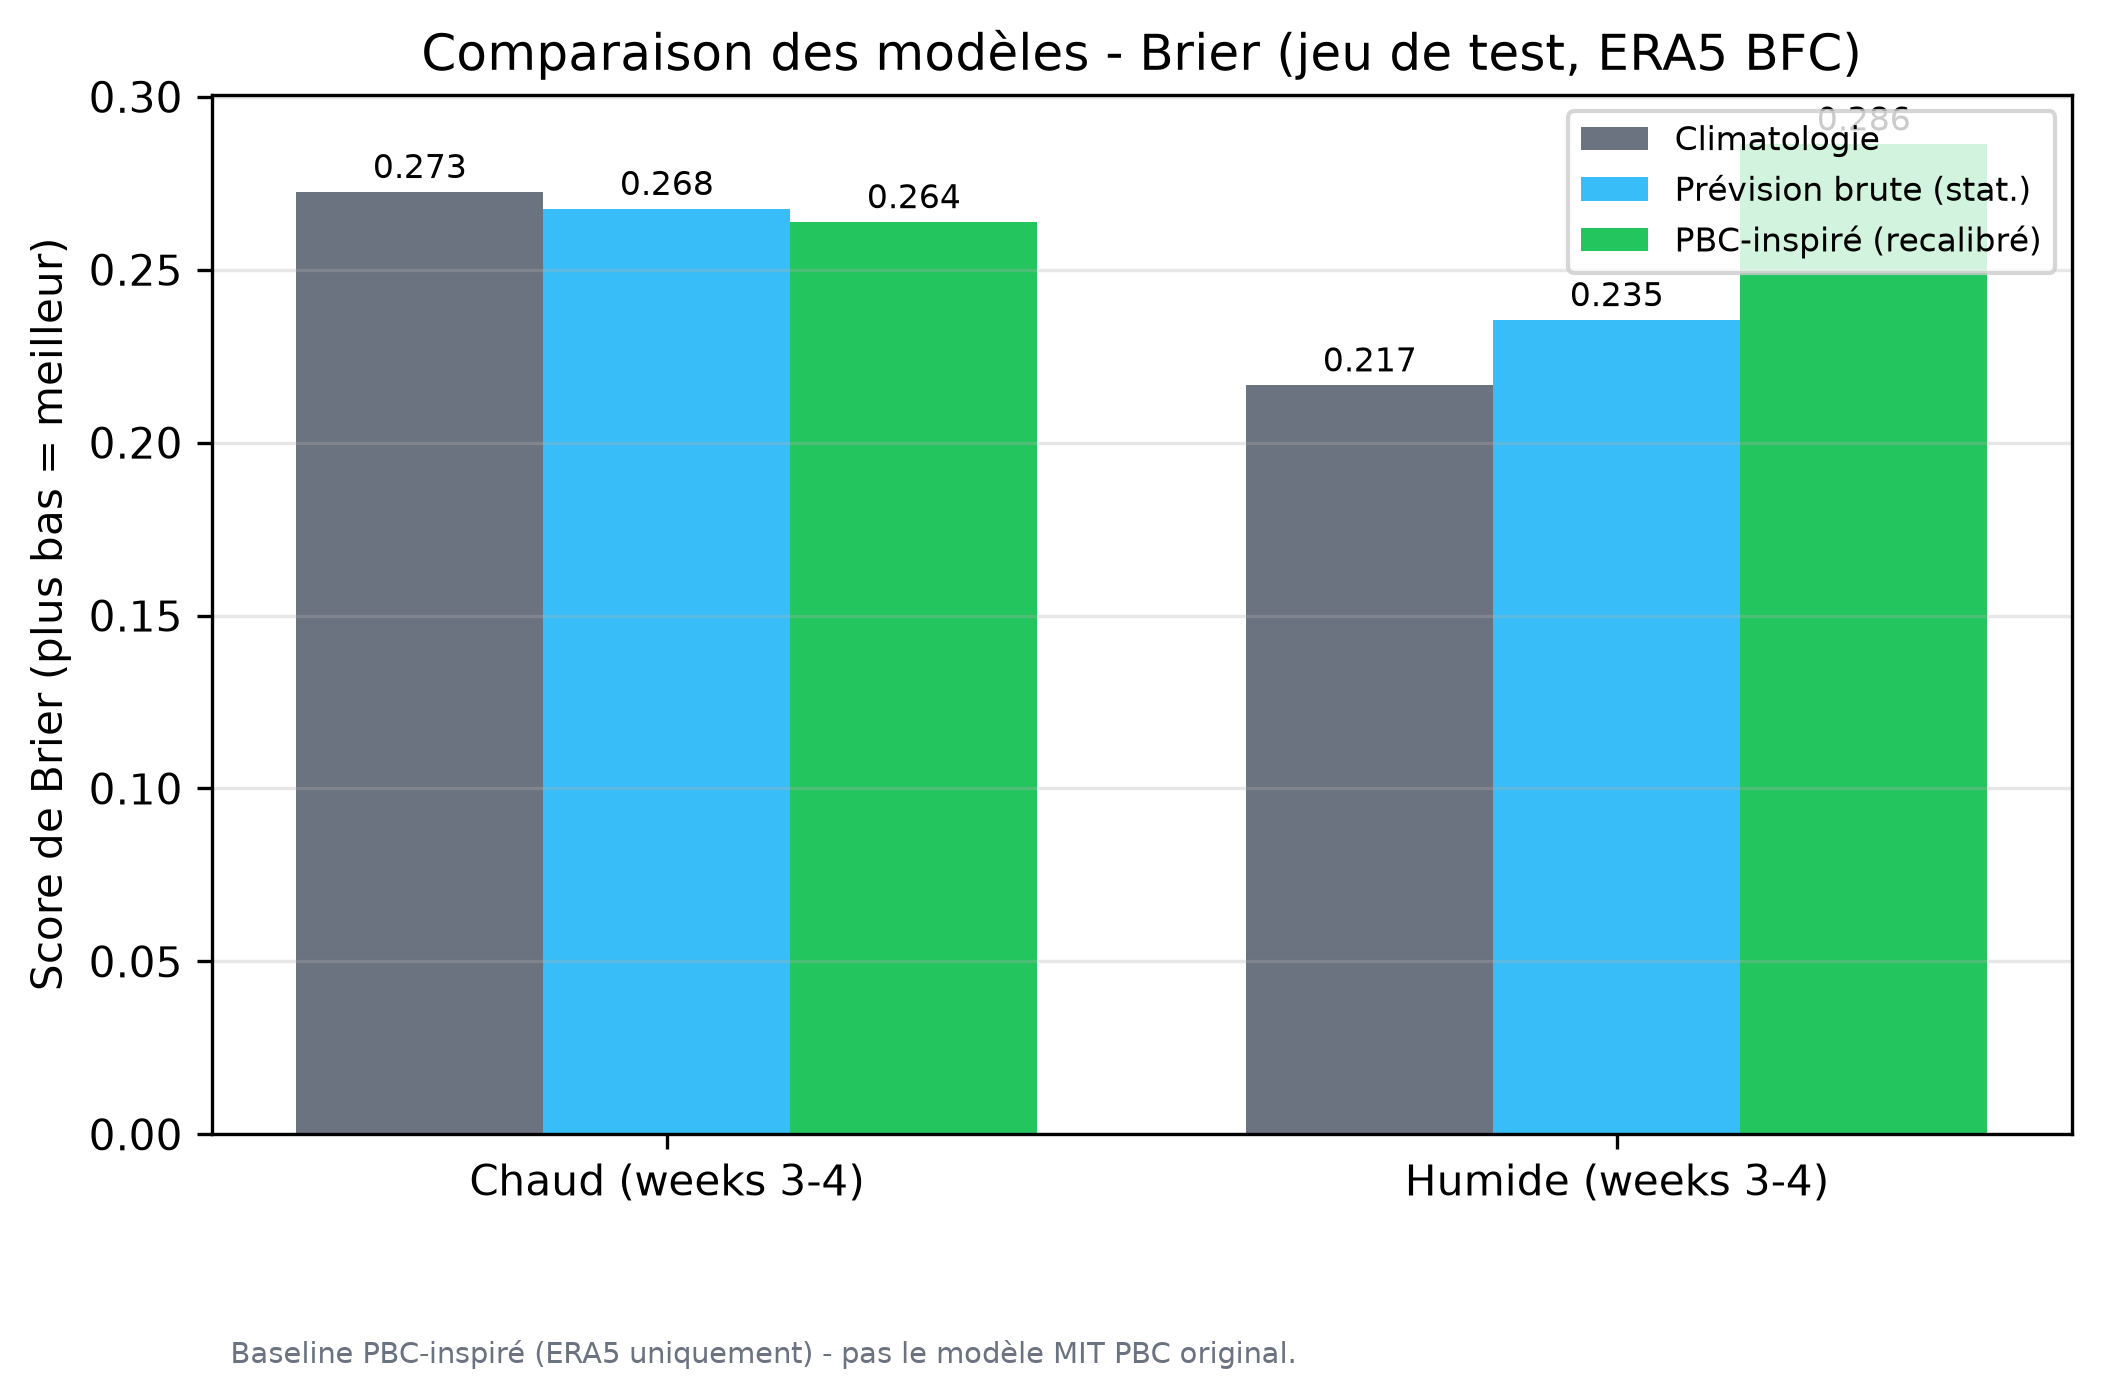

In [8]:
display(Image(filename=str(R.FIGDIR/'01_model_comparison.png')))

### 4.2 Reliability diagram - probabilistic calibration
**Interpretation:** points on the diagonal are perfectly calibrated. Recalibration should pull the PBC curve toward the diagonal relative to the raw forecast.

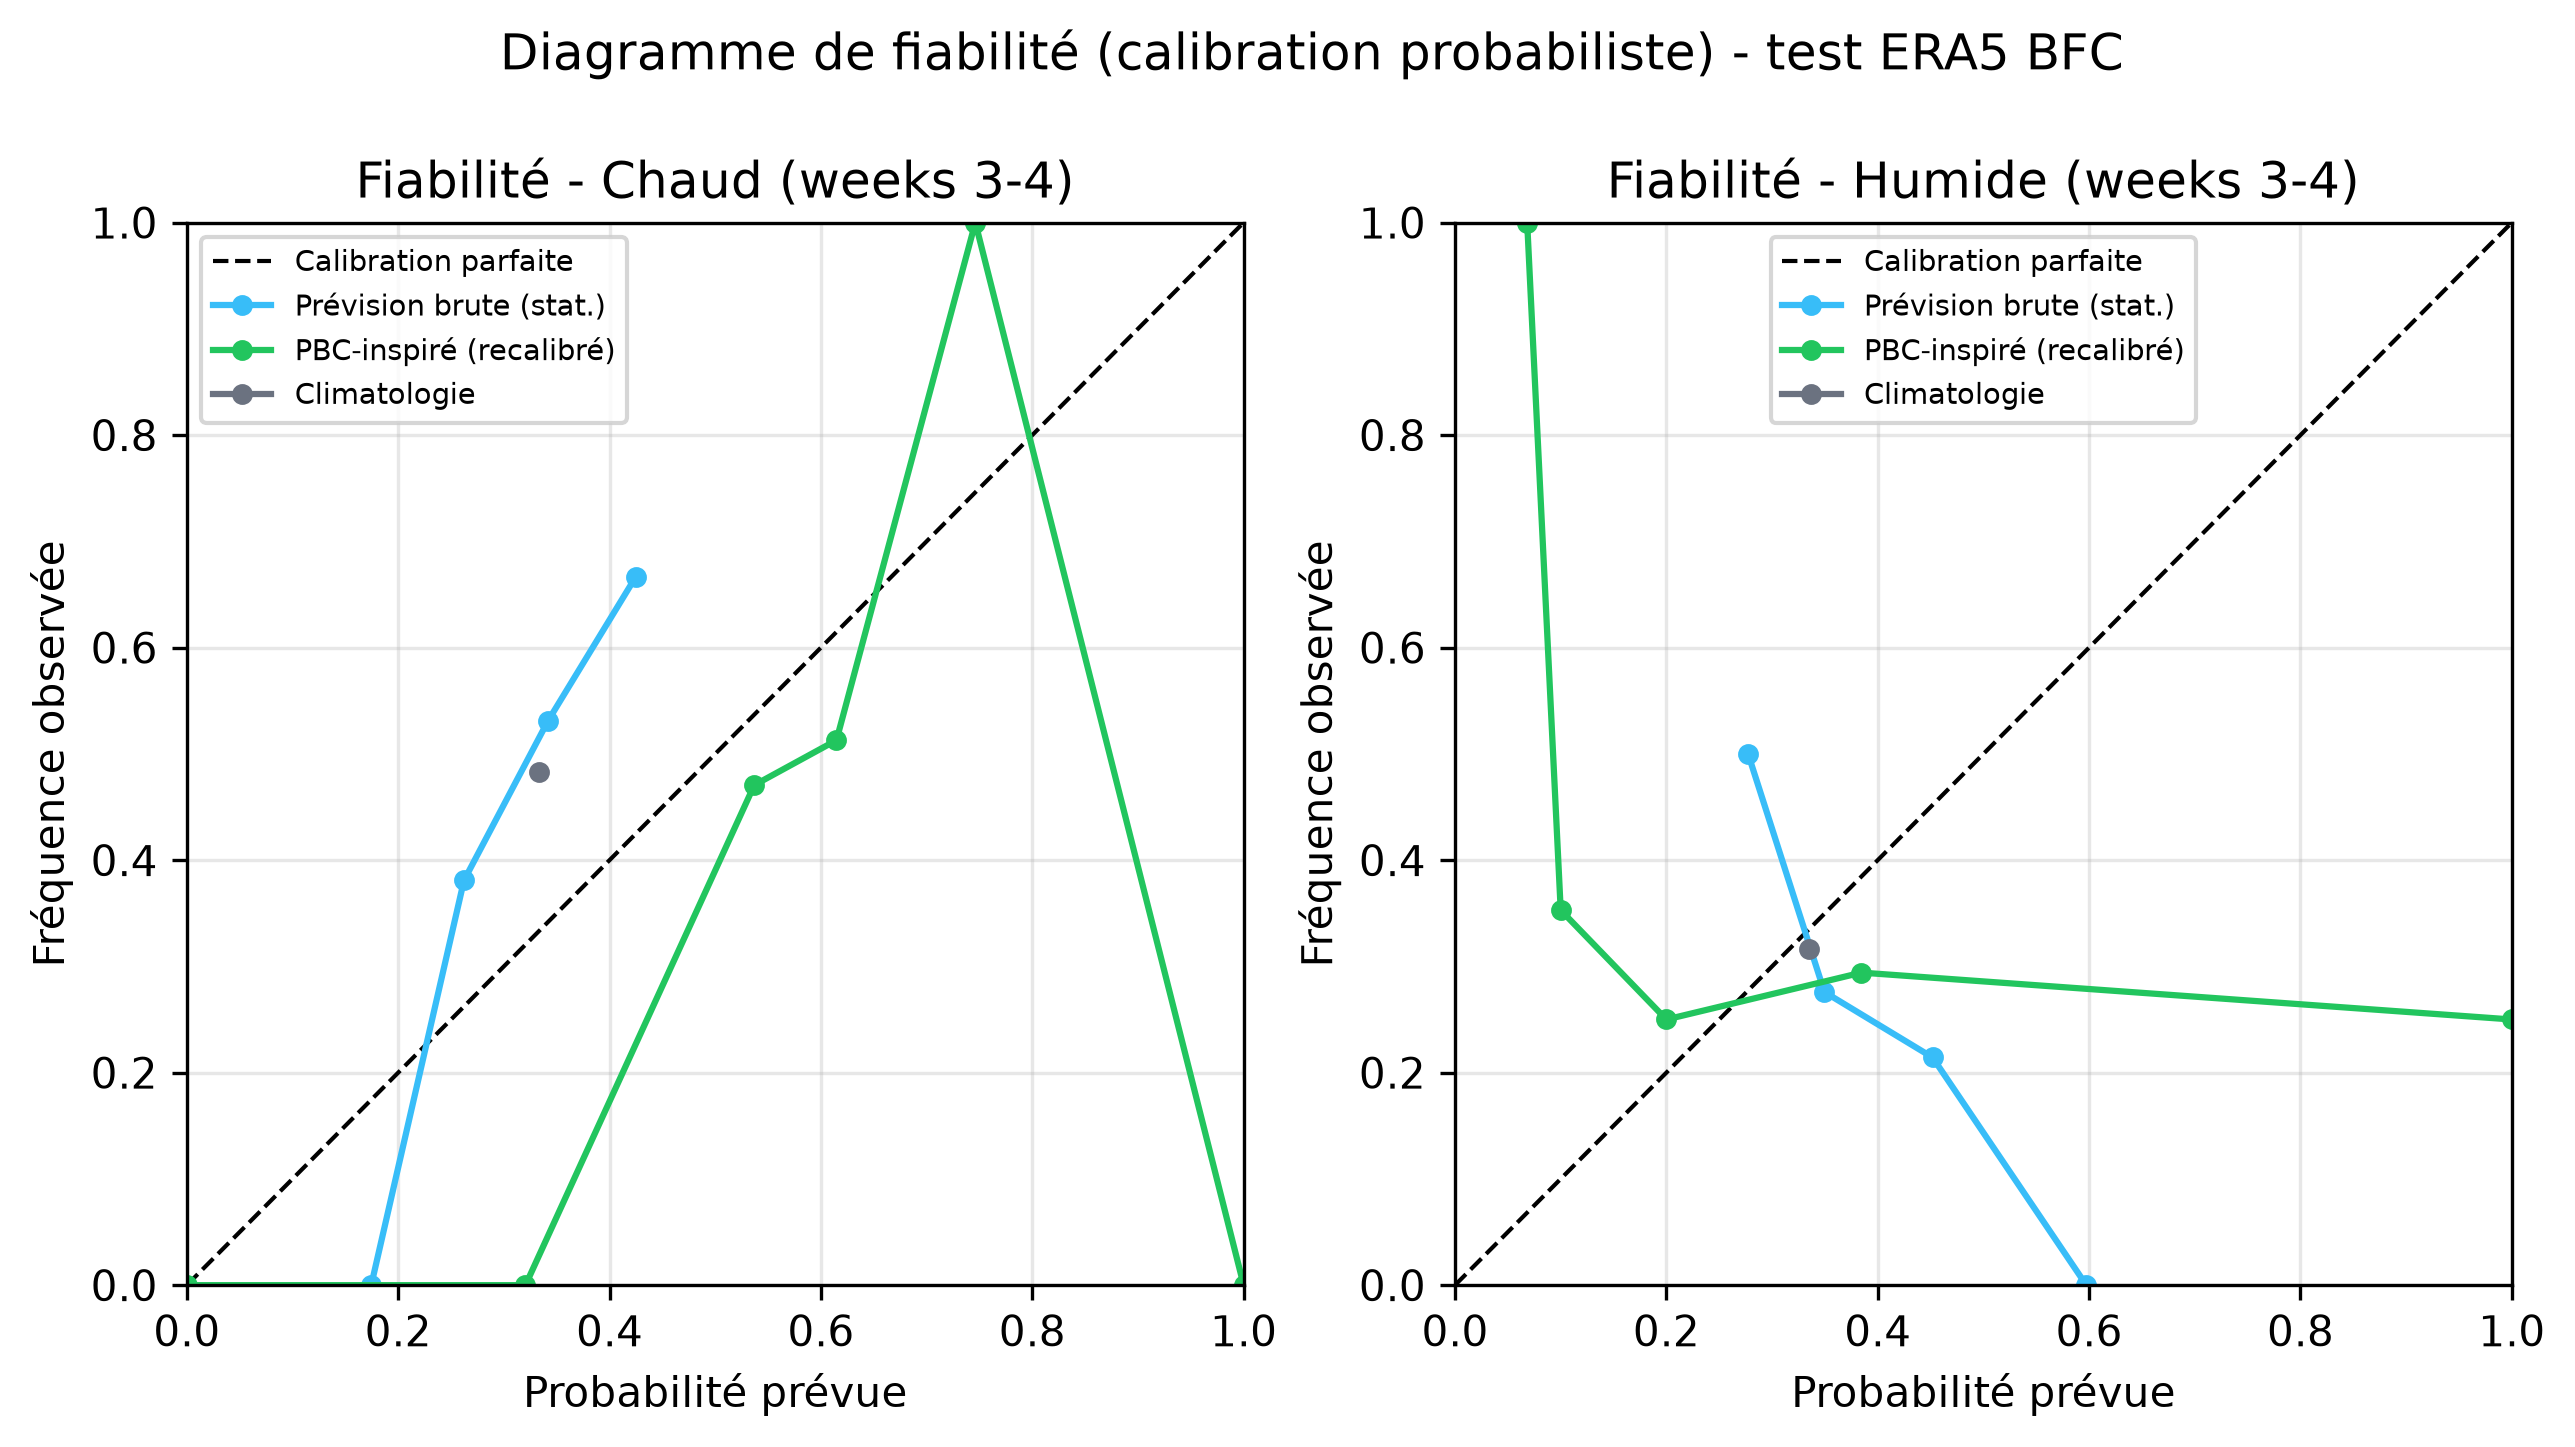

In [9]:
display(Image(filename=str(R.FIGDIR/'02_reliability_diagram.png')))

### 4.3 Historical predictions vs verified outcomes (test period)
**Interpretation:** the line is the PBC-inspired event probability per init; ticks mark whether the event was actually observed. This shows calibration and discrimination over time.

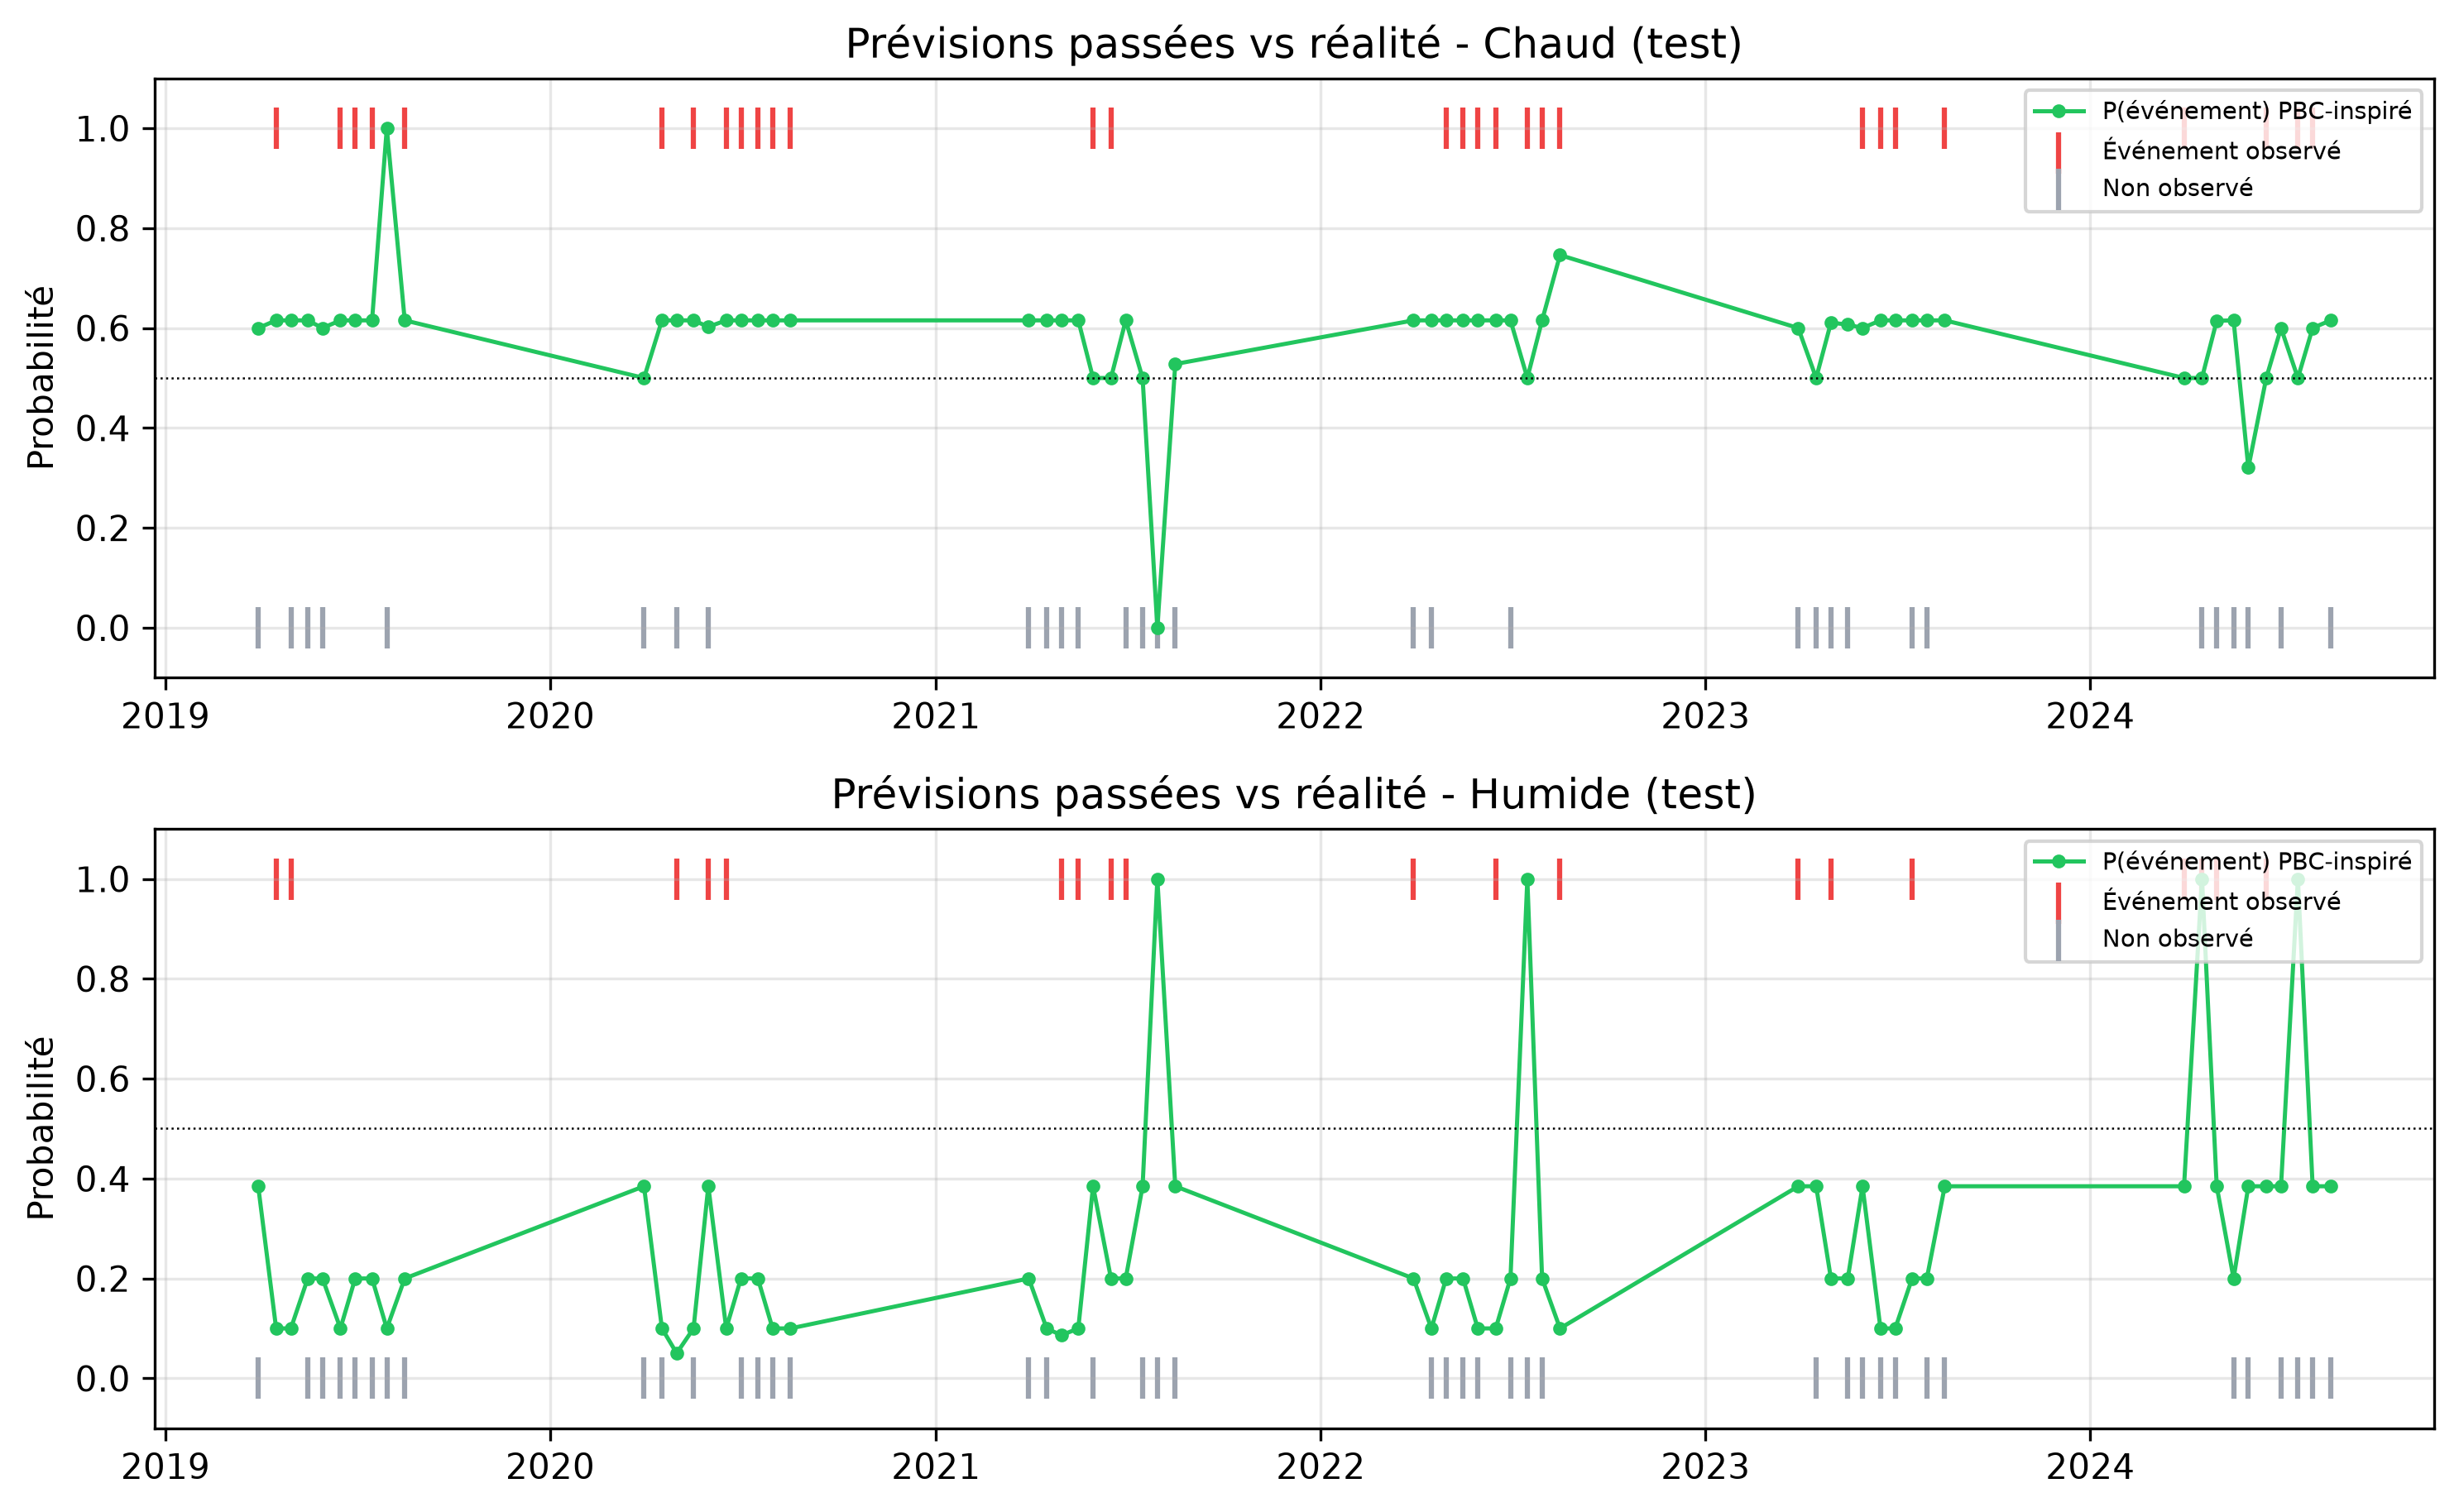

In [10]:
display(Image(filename=str(R.FIGDIR/'03_historical_predictions.png')))

### 4.4 Regional outlook - CLIMATOLOGICAL reference
**Why climatology:** the experiment did **not** demonstrate subseasonal skill beyond climatology (see §3.2), so presenting a 'skilful' probabilistic outlook would be misleading. We therefore show the **climatological** above-tercile probabilities by month across BFC - a scientifically supported baseline - clearly labelled as such.

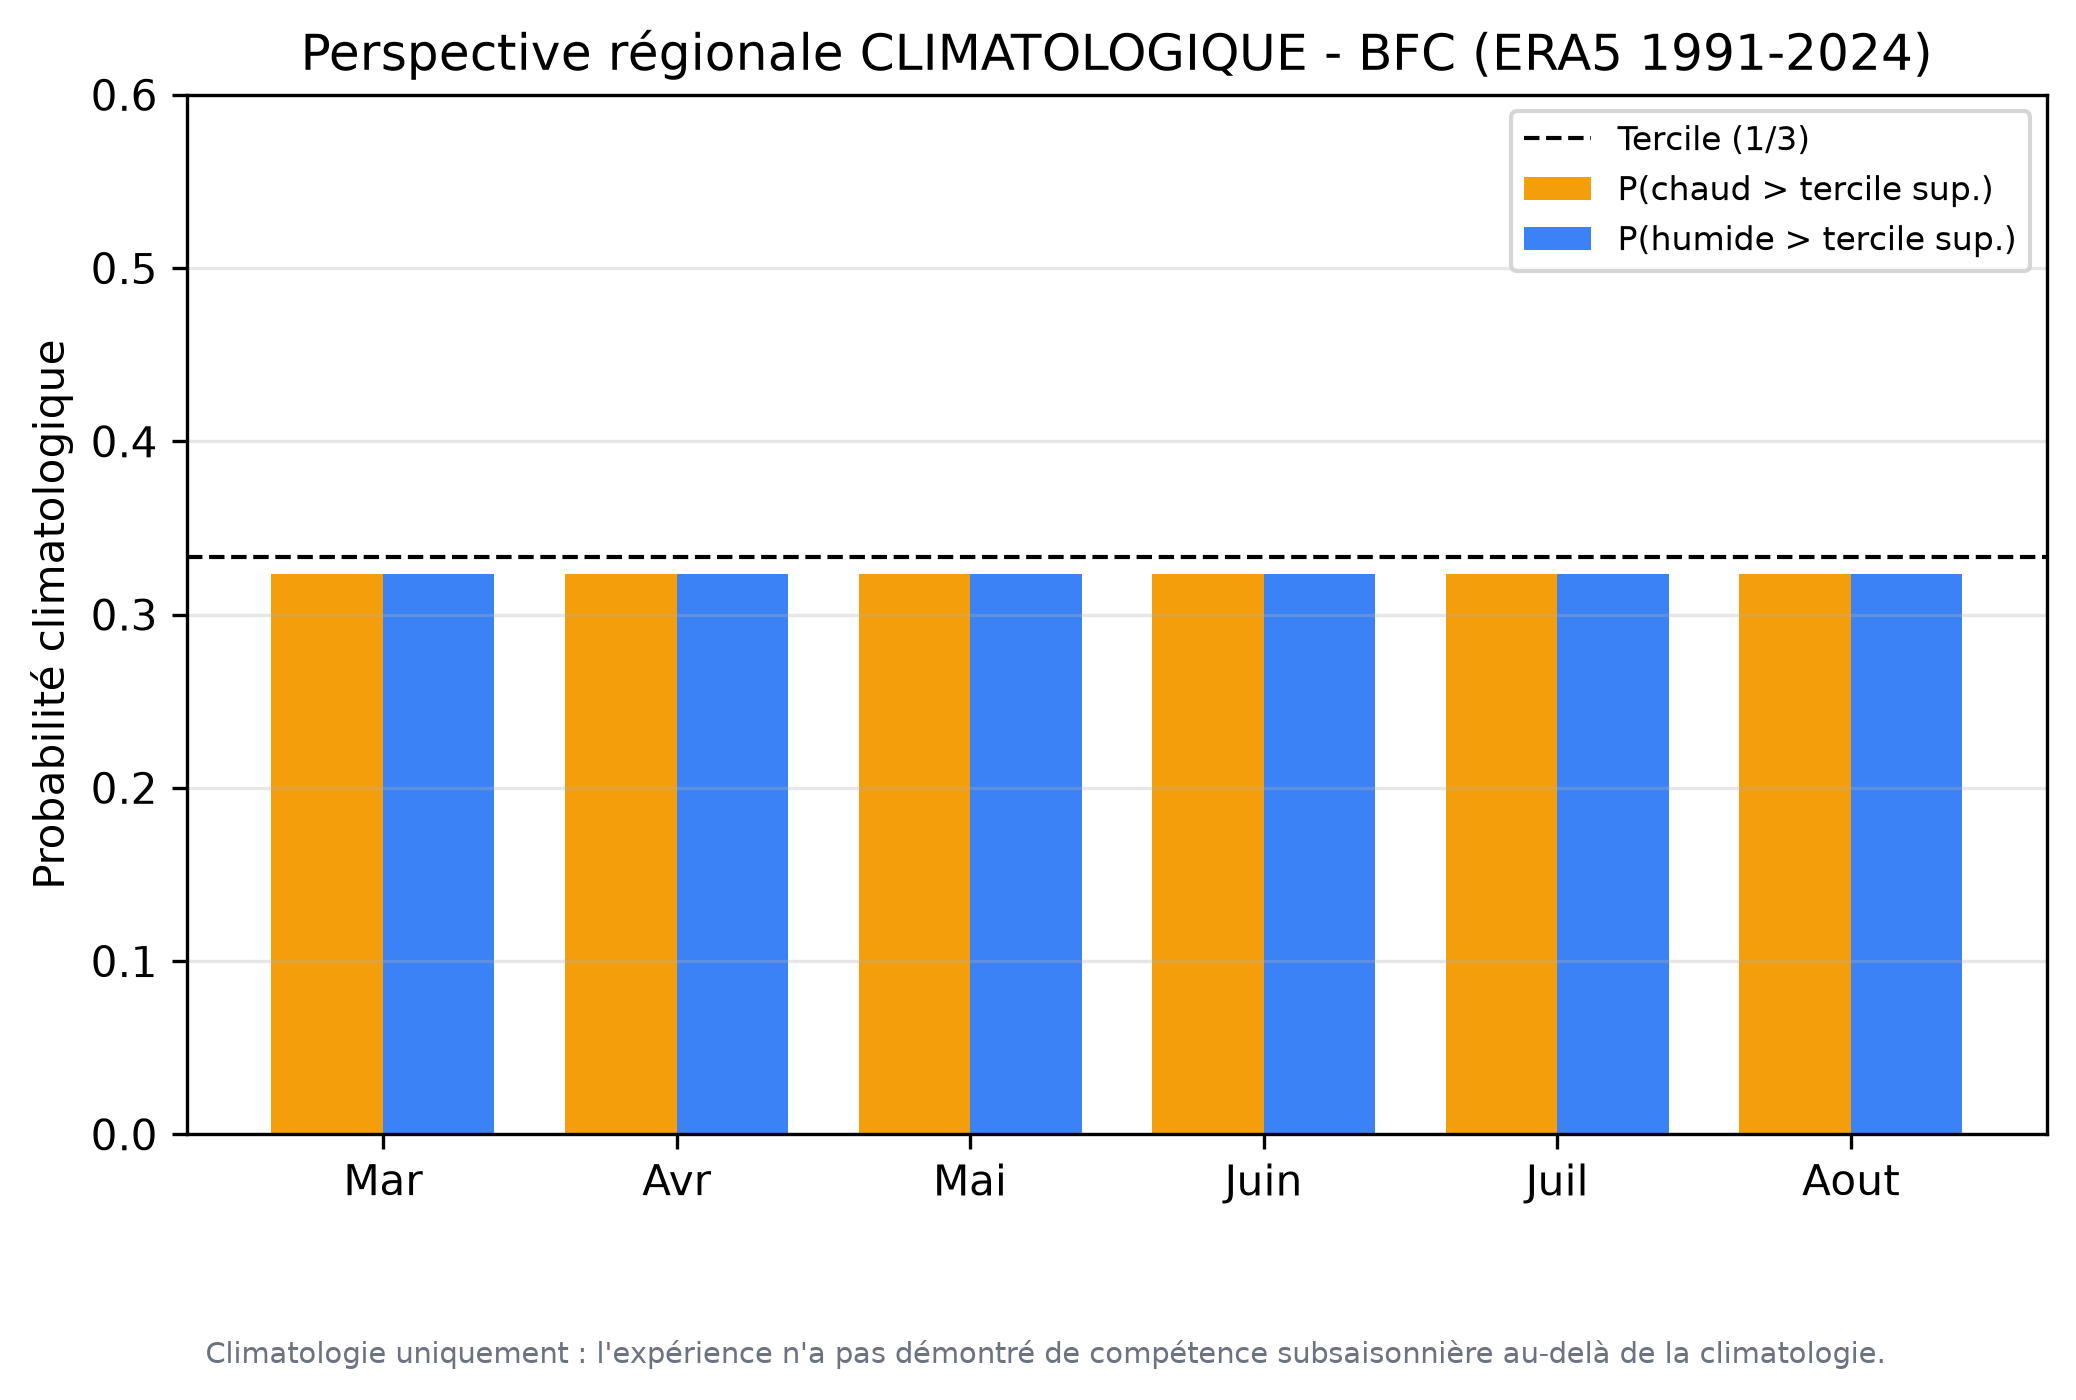

In [11]:
display(Image(filename=str(R.FIGDIR/'04_regional_outlook.png')))

## 5. Results summary & honest conclusion
Writes `reports/pbc/RESULTS.md`. The conclusion is driven by the held-out bootstrap: an improvement is reported **only** where the 95% CI supports it.

In [12]:
md_path = F.write_results_md(res)
print('Saved:', md_path.relative_to(REPO_ROOT))
warm = res['results']['warm']['boot_pbc_vs_clim']['improves']
wet  = res['results']['wet']['boot_pbc_vs_clim']['improves']
print(f'Demonstrable improvement over climatology -> warm: {warm} | wet: {wet}')
print(open(md_path).read()[:900])

Saved: reports/pbc/RESULTS.md
Demonstrable improvement over climatology -> warm: False | wet: False
# PBC-inspired subseasonal experiment - Results (Bourgogne-Franche-Comté)

_Generated: 2026-10-31T23:01:12.351796+00:00_

## Status

**Reduced, explicitly-labelled PBC-inspired calibration baseline** - NOT the original MIT PBC model (which requires licensed S2S hindcasts + large compute, unavailable here).

## Data (real)

- Observations: ERA5 reanalysis via Open-Meteo archive (`models=era5`), daily 2 m mean temperature (°C) and precipitation (mm), 1991-2024, 5 BFC points averaged.

- Forecast inputs: persistence++-inspired statistical predictors from ERA5 at initialisation (no licensed dynamical S2S hindcasts).

- Lead: weeks 3-4 (valid days 15-28). Event: above upper tercile (train-only thresholds).

## Sample sizes

- warm: {'train': 240, 'val': 40, 'test': 60} (train/val/test); test base rate = 0.483

- wet: {'train': 240, 'val': 40, 'test': 60} (train/val/test); test base rate = 0.3

## 6. Limitations & what would be needed to reproduce the full MIT PBC
- **Small samples** (weeks 3-4, one region, biweekly inits) → wide confidence intervals; numerical differences are mostly within noise.
- **Non-stationarity:** fixed train-period tercile thresholds are biased under the observed warming trend (recent warm-event frequency exceeds 1/3), which penalises the climatology reference and complicates attribution.
- **Reduced scope:** the 'raw forecast' is a statistical persistence model, **not** a dynamical/AI S2S ensemble. This is a methodological demonstration of PBC-style recalibration, **not** a reproduction of the Nature model.
- **To reproduce the real MIT PBC** one would need: licensed ECMWF/IRI S2S reforecasts, ERA5 via `cdsapi`, the `aiwqd` conda environment, and substantial compute - then apply Debias++/Persistence++ and the distributional projection on true ensembles.
- **Integrity:** all numbers and figures derive from real ERA5; no synthetic values are presented as observations; no yield/pesticide/economic/environmental claims are made.